In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [10]:
Data = pd.read_csv('xrd_vegard_linear_regression.csv')
Data.head(2)

,sample_id,Ge_content_at_pct,peak_111_two_theta_deg,lattice_parameter_A
0,X000,31.24,28.094,5.4997
1,X001,24.23,28.192,5.4770


In [14]:
Data['lattice_parameter_A'].shape

(200,)

Text(0, 0.5, 'Intensity')

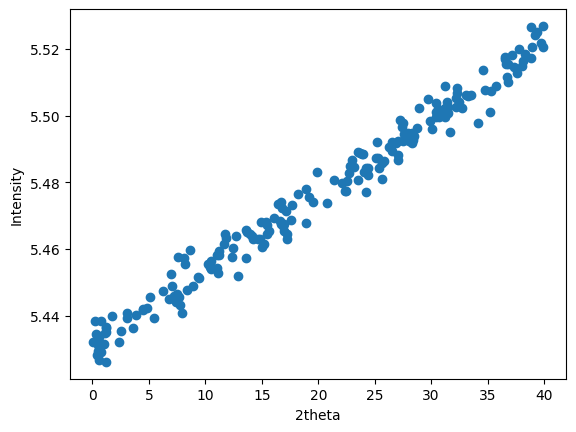

In [17]:
plt.scatter(Data['Ge_content_at_pct'],	Data['lattice_parameter_A'])
plt.xlabel('2theta')
plt.ylabel('Intensity')

In [32]:
X = Data[['Ge_content_at_pct']]
Y = Data[['lattice_parameter_A']]

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 2)


In [40]:
X_test

,Ge_content_at_pct
112,23.85
29,7.64
182,1.17
199,31.47
193,37.32
85,25.61
10,7.89
54,23.66
115,0.26
35,15.36


In [41]:
Y_test

,lattice_parameter_A
112,5.4886
29,5.4457
182,5.4367
199,5.5008
193,5.5146
85,5.4809
10,5.4407
54,5.4887
115,5.4383
35,5.4681


In [34]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Ge_content_at_pct']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[5.43]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [39]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

Y_pred = lr.predict(X_test)

print('r2 score is', r2_score(Y_pred, Y_test))
print('MAE is', mean_absolute_error(Y_pred, Y_test))
print('MSE is', mean_squared_error(Y_pred, Y_test))

r2 score is 0.9713923967669429
MAE is 0.0036529292688993074
MSE is 1.9499530118260633e-05


In [44]:
lr.predict(X_test.iloc[5].values.reshape(1, 1))

C:\Users\lands\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([[5.48909155]])

Text(0, 0.5, 'Intensity')

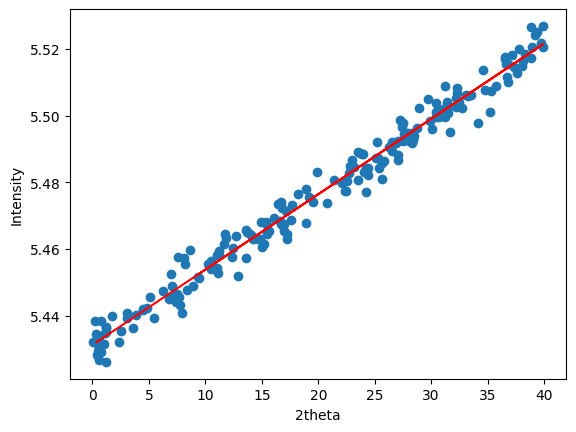

In [47]:
plt.scatter(Data['Ge_content_at_pct'],	Data['lattice_parameter_A'])
plt.plot(X_train, lr.predict(X_train), color = 'red')
plt.xlabel('2theta')
plt.ylabel('Intensity')

Text(0, 0.5, 'Intensity')

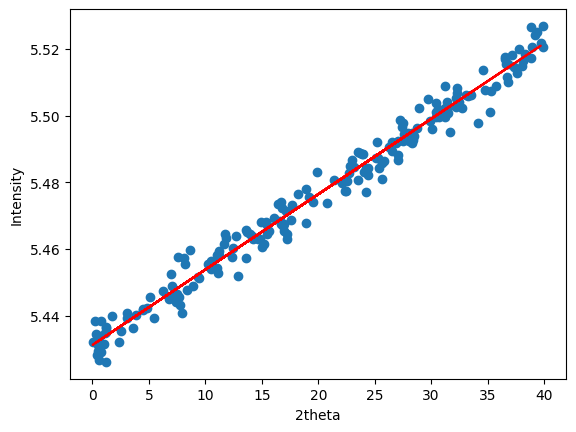

In [48]:
plt.scatter(Data['Ge_content_at_pct'],	Data['lattice_parameter_A'])
plt.plot(X_test, lr.predict(X_test), color = 'red')
plt.xlabel('2theta')
plt.ylabel('Intensity')

### slope and intercept value 

In [49]:
m = lr.coef_

In [50]:
b = lr.intercept_

In [52]:
## y = mx + b

m * 25.61 + b   ## we got the same value as predicted

array([[5.48909155]])

In [54]:
m * 3.56 + b

array([[5.43923989]])